# Tesis NHANES – Parte final B (local): consenso, DeLong, curvas de decisión y calibración

Continuación de `tesis_parte_final_local.ipynb` en un **kernel nuevo**. En el Mac, la memoria del chip gráfico no se recupera por completo después del SHAP de TabPFN; por eso estos pasos se ejecutan en un proceso aparte. Se reutilizan los resultados guardados por la parte A:
- `comparacion_importancia_shap.csv`: importancias SHAP de RF, XGBoost y TabPFN, de las que se recalculan la parsimonia y el consenso con la misma regla.
- `probabilidades_test.csv`: probabilidades en test de los 4 modelos, que se usan en las curvas de decisión y la calibración.
- `tabla_metricas_test.csv`: métricas en test, incluido el Brier.

TabPFN se reentrena con los mismos parámetros y la misma semilla, y se verifica que reproduce las probabilidades de la parte A.

In [1]:
# Nota (macOS): el kernel "Python (tesis_nhanes)" arranca con DYLD_LIBRARY_PATH apuntando a torch/lib,
# para que XGBoost y PyTorch compartan la misma librería OpenMP (con dos copias el proceso se cae o se congela).
# --- Python ---
import os
import time
import random
import warnings
from pathlib import Path

# --- Datos ---
import numpy as np
import pandas as pd

# --- Visualización ---
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import matplotlib.colors as mcolors
import seaborn as sns

# --- Estadística ---
import scipy.stats as stats
from scipy.stats import spearmanr

# --- Machine Learning ---
from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, RandomizedSearchCV, cross_validate
from sklearn.calibration import calibration_curve
from sklearn.metrics import (
    roc_auc_score, roc_curve, average_precision_score, accuracy_score, precision_score,
    f1_score, brier_score_loss, confusion_matrix, classification_report, ConfusionMatrixDisplay,
)
from sklearn.ensemble import RandomForestClassifier
from tabpfn import TabPFNClassifier
from tabpfn.constants import ModelVersion

# --- Interpretabilidad ---
import shap
from tabpfn_extensions.interpretability.shapiq import get_tabpfn_imputation_explainer
from tabpfn_extensions.interpretability import shapiq_to_shap_explanation

import joblib

/Users/mcamilavt/tesis_nhanes_local/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

DATA_DIR    = Path.home() / "Downloads"
RESULTS_DIR = Path.home() / "tesis_nhanes_local" / "resultados"
FIG_DIR     = RESULTS_DIR / "figuras"
FIG_DIR.mkdir(parents=True, exist_ok=True)

TARGET = "RESISTENCIA_INSULINA"
N_FOLDS, N_ITER_BUSQUEDA = 5, 50
cv = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
ALFA = 0.05

N_SHAP = 458
BUDGET_SHAP_TABPFN = 256
UMBRAL_IMPORTANCIA_ACUMULADA = 0.85
N_TOP_HEATMAP = 15
UMBRALES_DCA = np.round(np.arange(0.01, 1.00, 0.01), 2)
UMBRALES_DCA_TABLA = [0.10, 0.20, 0.30, 0.40, 0.50, 0.60]
ETIQUETAS_CLASES = ["Sin RI", "Con RI"]

TABPFN_DEVICE = "mps"   # chip gráfico del Mac: ~8 veces más rápido que la CPU en la prueba de velocidad

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 250)
warnings.filterwarnings("ignore", category=FutureWarning)


def guardar_figura(nombre, dpi=300):
    plt.savefig(FIG_DIR / nombre, dpi=dpi, bbox_inches="tight")

In [3]:
train_modelo = pd.read_csv(DATA_DIR / "train_modelo.csv")
test_modelo = pd.read_csv(DATA_DIR / "test_modelo.csv")
X_train, y_train = train_modelo.drop(columns=[TARGET]), train_modelo[TARGET].astype(int)
X_test, y_test = test_modelo.drop(columns=[TARGET]), test_modelo[TARGET].astype(int)

rf = joblib.load(DATA_DIR / "modelo_random_forest (2).pkl")
svm = joblib.load(DATA_DIR / "modelo_svm.pkl")
xgb = joblib.load(DATA_DIR / "modelo_xgboost.pkl")

probabilidades = pd.read_csv(RESULTS_DIR / "probabilidades_test.csv")
assert (probabilidades["y_test"].to_numpy() == y_test.to_numpy()).all()
metricas_test = pd.read_csv(RESULTS_DIR / "tabla_metricas_test.csv", index_col=0)
resultados_test = {m: {"y_prob": probabilidades[m].to_numpy(), "metricas": metricas_test.loc[m].to_dict()}
                   for m in ["Random Forest", "SVM", "XGBoost", "TabPFN"]}

In [4]:
# Licencia/token: el token se lee de ~/tesis_nhanes_local/.tabpfn_token (nunca se escribe en el notebook)
ruta_token = Path.home() / "tesis_nhanes_local" / ".tabpfn_token"
if "TABPFN_TOKEN" not in os.environ and ruta_token.exists():
    os.environ["TABPFN_TOKEN"] = ruta_token.read_text().strip()

RUTA_MODELO_TABPFN = TabPFNClassifier.create_default_for_version(ModelVersion.V2_5).model_path
TABPFN_PARAMS = {"model_path": RUTA_MODELO_TABPFN, "n_estimators": 32, "balance_probabilities": True,
                 "random_state": SEED, "device": TABPFN_DEVICE}
# fit_with_cache (caché de ~6 GB en la memoria del chip gráfico) solo se usa para SHAP (sección 15.2):
# no cambia las predicciones, y activarla aquí agota la memoria en la validación cruzada.
print(f"Modelo TabPFN: {RUTA_MODELO_TABPFN} | dispositivo: {TABPFN_DEVICE}")

t0 = time.time()
modelo_tabpfn = TabPFNClassifier(**TABPFN_PARAMS)
modelo_tabpfn.fit(X_train, y_train)
# No se guarda con joblib: con fit_mode="fit_with_cache" el archivo incluye la caché y ocupa > 6 GB.
# Se reproduce reentrenando con TABPFN_PARAMS (determinista con random_state); las probabilidades se guardan en la sección 14.
print(f"TabPFN entrenado en {time.time() - t0:.0f} s")

# Verificación: el TabPFN reentrenado reproduce las probabilidades de la parte A
assert np.allclose(modelo_tabpfn.predict_proba(X_test)[:, 1], resultados_test["TabPFN"]["y_prob"], atol=1e-4)
print("TabPFN reproduce las probabilidades de la parte A")

Modelo TabPFN: /Users/mcamilavt/Library/Caches/tabpfn/tabpfn-v2.5-classifier-v2.5_default.ckpt | dispositivo: mps


TabPFN entrenado en 0 s


TabPFN reproduce las probabilidades de la parte A


## 15.3–15.4 Parsimonia y consenso (a partir de las importancias SHAP de la parte A)

In [5]:
comparacion = pd.read_csv(RESULTS_DIR / "comparacion_importancia_shap.csv")
importancia_rf, importancia_xgb, importancia_tabpfn = (
    comparacion[["variable", f"mean_abs_shap_{m}"]].sort_values(f"mean_abs_shap_{m}", ascending=False).reset_index(drop=True)
    for m in ["rf", "xgb", "tabpfn"])

In [6]:
def analizar_parsimonia(df_importancia, columna_shap, nombre_modelo, umbral=UMBRAL_IMPORTANCIA_ACUMULADA):
    """Número mínimo de variables que acumulan `umbral` de la importancia SHAP total."""
    df = df_importancia.copy()
    df["proporcion"] = df[columna_shap] / df[columna_shap].sum()
    df = df.sort_values("proporcion", ascending=False).reset_index(drop=True)
    df["importancia_acumulada"] = df["proporcion"].cumsum()
    df["n_variables"] = np.arange(1, len(df) + 1)
    n_variables = df.loc[df["importancia_acumulada"] >= umbral, "n_variables"].iloc[0]
    variables = df.iloc[:n_variables]["variable"].tolist()
    print(f"{nombre_modelo}: {n_variables} variables para el {umbral:.0%} → {variables}")
    return df, n_variables, variables


tabla_rf, n_rf, variables_rf = analizar_parsimonia(importancia_rf, "mean_abs_shap_rf", "Random Forest")
tabla_xgb, n_xgb, variables_xgb = analizar_parsimonia(importancia_xgb, "mean_abs_shap_xgb", "XGBoost")
tabla_tabpfn, n_tabpfn, variables_tabpfn = analizar_parsimonia(importancia_tabpfn, "mean_abs_shap_tabpfn", "TabPFN")

n_predictores = X_train.shape[1]
resumen_parsimonia = pd.DataFrame({
    "Modelo": ["Random Forest", "XGBoost", "TabPFN"],
    f"n_variables_{UMBRAL_IMPORTANCIA_ACUMULADA:.0%}": [n_rf, n_xgb, n_tabpfn],
    f"% del total ({n_predictores} var)": [round(n / n_predictores * 100, 1) for n in [n_rf, n_xgb, n_tabpfn]],
})
resumen_parsimonia

Random Forest: 18 variables para el 85% → ['IMC', 'CINTURA', 'TRIGLICERIDOS', 'COLESTEROL_HDL', 'BRAZO', 'CADERA', 'VITAMINA_D', 'ALT', 'PROTEINA_C_REACTIVA', 'PULSO', 'EDAD', 'HIERRO', 'PAD', 'COLESTEROL_LDL', 'INGESTA_FIBRA', 'CPK', 'INGESTA_AZUCAR', 'INGESTA_CALORIAS']
XGBoost: 18 variables para el 85% → ['CINTURA', 'TRIGLICERIDOS', 'IMC', 'ALT', 'VITAMINA_D', 'PULSO', 'COLESTEROL_HDL', 'BRAZO', 'EDAD', 'PROTEINA_C_REACTIVA', 'AST', 'HIERRO', 'DX_HIPERTENSION', 'INGESTA_PROTEINA', 'CADERA', 'MAS_100_CIGARRILLOS', 'COLESTEROL_LDL', 'INGESTA_AZUCAR']
TabPFN: 16 variables para el 85% → ['CINTURA', 'ALT', 'IMC', 'TRIGLICERIDOS', 'AST', 'COLESTEROL_HDL', 'PULSO', 'EDAD', 'MAS_100_CIGARRILLOS', 'VITAMINA_D', 'ETNIA_Asiatico_no_Hispano', 'DX_HIPERTENSION', 'PROTEINA_C_REACTIVA', 'USO_HIPOLIPEMIANTES', 'HIERRO', 'CADERA']


,Modelo,n_variables_85%,% del total (43 var)
0,Random Forest,18,41.9
1,XGBoost,18,41.9
2,TabPFN,16,37.2


In [7]:
variables_consenso = [v for v in variables_rf if v in set(variables_xgb) & set(variables_tabpfn)]
assert variables_consenso, "La intersección de los tres subconjuntos parsimoniosos está vacía"

consenso_pct = [round(len(variables_consenso) / n * 100, 1) for n in [n_rf, n_xgb, n_tabpfn]]
print(f"Variables de consenso ({len(variables_consenso)}): {variables_consenso}")
print(f"% de las variables de cada modelo incluidas en el consenso (RF, XGB, TabPFN): {consenso_pct}")

X_train_consenso = X_train[variables_consenso]
X_test_consenso = X_test[variables_consenso]

Variables de consenso (11): ['IMC', 'CINTURA', 'TRIGLICERIDOS', 'COLESTEROL_HDL', 'CADERA', 'VITAMINA_D', 'ALT', 'PROTEINA_C_REACTIVA', 'PULSO', 'EDAD', 'HIERRO']
% de las variables de cada modelo incluidas en el consenso (RF, XGB, TabPFN): [np.float64(61.1), np.float64(61.1), np.float64(68.8)]


In [8]:
scoring_consenso = {"acc": "accuracy", "auc": "roc_auc", "f1": "f1"}

filas = []
modelos_cv = {"RF": rf, "SVM": svm, "XGBoost": xgb, "TabPFN": modelo_tabpfn}
for nombre, modelo in modelos_cv.items():
    for etiqueta, X_cv in [(f"Completo ({X_train.shape[1]} var)", X_train),
                           (f"Consenso ({len(variables_consenso)} var)", X_train_consenso)]:
        print(f"Evaluando {nombre} - {etiqueta}...")
        res = cross_validate(clone(modelo), X_cv, y_train, cv=cv, scoring=scoring_consenso, n_jobs=1, error_score="raise")
        filas.append({"Modelo": nombre, "Conjunto de variables": etiqueta,
                      "AUC-ROC": round(res["test_auc"].mean(), 4), "Accuracy": round(res["test_acc"].mean(), 4),
                      "F1-Score": round(res["test_f1"].mean(), 4)})

tabla_consenso = pd.DataFrame(filas)
tabla_consenso.to_csv(RESULTS_DIR / "tabla_comparacion_consenso.csv", index=False)

pivote = tabla_consenso.pivot(index="Modelo", columns="Conjunto de variables", values="AUC-ROC")
pivote["Diferencia AUC-ROC"] = pivote.iloc[:, 0] - pivote.iloc[:, 1]   # completo - consenso
pivote

Evaluando RF - Completo (43 var)...


Evaluando RF - Consenso (11 var)...


Evaluando SVM - Completo (43 var)...


Evaluando SVM - Consenso (11 var)...


Evaluando XGBoost - Completo (43 var)...


Evaluando XGBoost - Consenso (11 var)...


Evaluando TabPFN - Completo (43 var)...


Evaluando TabPFN - Consenso (11 var)...


Conjunto de variables,Completo (43 var),Consenso (11 var),Diferencia AUC-ROC
Modelo,,,
RF,0.8508,0.8444,0.0064
SVM,0.8468,0.8420,0.0048
TabPFN,0.8653,0.8592,0.0061
XGBoost,0.8581,0.8512,0.0069


## 15.5 Prueba de DeLong

In [9]:
def _compute_midrank(x):
    J = np.argsort(x)
    Z = x[J]
    N = len(x)
    T = np.zeros(N, dtype=float)
    i = 0
    while i < N:
        j = i
        while j < N and Z[j] == Z[i]:
            j += 1
        T[i:j] = 0.5 * (i + j - 1) + 1
        i = j
    T2 = np.empty(N, dtype=float)
    T2[J] = T
    return T2


def delong_test(y_true, pred_a, pred_b):
    """Prueba de DeLong pareada para comparar dos curvas ROC sobre las mismas observaciones."""
    y_true = np.asarray(y_true)
    order = (-y_true).argsort()
    preds = np.vstack([pred_a[order], pred_b[order]])
    m = int(y_true.sum())   # positivos
    n = len(y_true) - m     # negativos

    tx_rank = np.array([_compute_midrank(p[:m]) for p in preds])
    ty_rank = np.array([_compute_midrank(p[m:]) for p in preds])
    tz_rank = np.array([_compute_midrank(p) for p in preds])

    aucs = tz_rank[:, :m].sum(axis=1) / (m * n) - (m + 1.0) / (2.0 * n)
    v01 = (tz_rank[:, :m] - tx_rank) / n
    v10 = 1.0 - (tz_rank[:, m:] - ty_rank) / m
    delongcov = np.cov(v01) / m + np.cov(v10) / n

    l = np.array([1, -1])
    diff_auc = l @ aucs
    z = diff_auc / np.sqrt(l @ delongcov @ l)
    p = 2 * (1 - stats.norm.cdf(abs(z)))
    return diff_auc, z, p, aucs[0], aucs[1]

In [10]:
resultados_delong = []
for nombre, modelo in modelos_cv.items():
    print(f"Entrenando {nombre} con las variables de consenso...")
    pred_completo = modelo.predict_proba(X_test)[:, 1]
    pred_consenso = clone(modelo).fit(X_train_consenso, y_train).predict_proba(X_test_consenso)[:, 1]
    diff, z, p, auc_completo, auc_consenso = delong_test(y_test.values, pred_completo, pred_consenso)
    resultados_delong.append({"Modelo": nombre, "AUC completo": round(auc_completo, 4),
                              "AUC consenso": round(auc_consenso, 4), "Diferencia": round(diff, 4),
                              "z": round(z, 3), "p-valor": round(p, 4),
                              "Significativo (α=0.05)": "Sí" if p < ALFA else "No"})

tabla_delong = pd.DataFrame(resultados_delong)
tabla_delong.to_csv(RESULTS_DIR / "tabla_delong.csv", index=False)
tabla_delong

Entrenando RF con las variables de consenso...
Entrenando SVM con las variables de consenso...


Entrenando XGBoost con las variables de consenso...
Entrenando TabPFN con las variables de consenso...


,Modelo,AUC completo,AUC consenso,Diferencia,z,p-valor,Significativo (α=0.05)
0,RF,0.8408,0.8355,0.0053,0.819,0.4129,No
1,SVM,0.8409,0.8345,0.0065,0.631,0.5278,No
2,XGBoost,0.8496,0.8352,0.0144,2.438,0.0148,Sí
3,TabPFN,0.8606,0.8506,0.0100,1.678,0.0933,No


## 15.6 Mapa de calor de importancia relativa

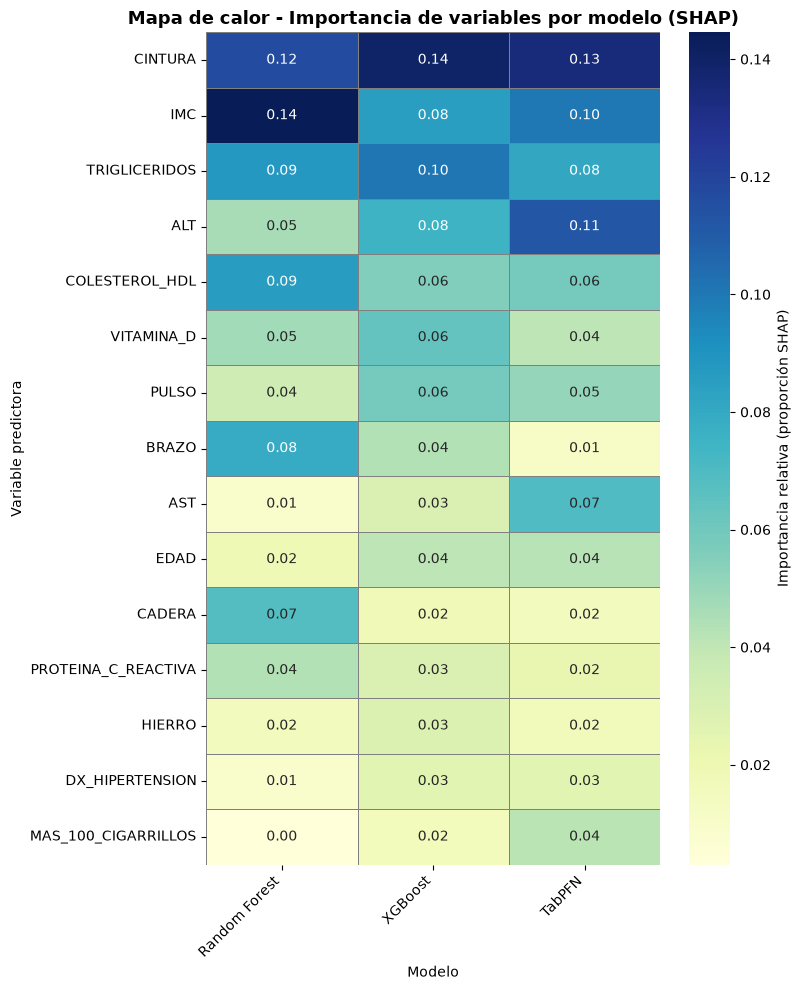

In [11]:
prop = pd.DataFrame({"Random Forest": tabla_rf.set_index("variable")["proporcion"],
                     "XGBoost": tabla_xgb.set_index("variable")["proporcion"],
                     "TabPFN": tabla_tabpfn.set_index("variable")["proporcion"]})
prop = prop.loc[prop.mean(axis=1).sort_values(ascending=False).index[:N_TOP_HEATMAP]]

fig, ax = plt.subplots(figsize=(8, 0.5 * N_TOP_HEATMAP + 2.5))
sns.heatmap(prop, annot=True, fmt=".2f", cmap="YlGnBu", linewidths=0.5, linecolor="gray",
            cbar_kws={"label": "Importancia relativa (proporción SHAP)"}, ax=ax)
ax.set_title("Mapa de calor - Importancia de variables por modelo (SHAP)", fontsize=13, fontweight="bold")
ax.set_xlabel("Modelo")
ax.set_ylabel("Variable predictora")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
guardar_figura("heatmap_importancia_modelos.png")
plt.show()

## 16. Curvas de decisión clínica (Decision Curve Analysis) y calibración

El análisis de curvas de decisión (Vickers & Elkin, 2006) evalúa la **utilidad clínica** de cada modelo: si usarlo para decidir a quién intervenir (p. ej., solicitar una evaluación metabólica completa o iniciar una intervención de estilo de vida) produce más beneficio que las estrategias por defecto de intervenir a todos o a nadie.

Para cada probabilidad umbral *pₜ* (la probabilidad de RI a partir de la cual el clínico intervendría):

$$\text{Beneficio neto} = \frac{VP}{n} - \frac{FP}{n}\cdot\frac{p_t}{1-p_t}$$

El factor *pₜ/(1−pₜ)* expresa cuántos falsos positivos se aceptan por cada verdadero positivo: con *pₜ* = 0,20 se acepta intervenir a 4 personas sin RI por cada persona con RI detectada. Un modelo tiene utilidad clínica en los umbrales donde su curva está por encima de las de "intervenir a todos" y "no intervenir a nadie". Se calcula en el conjunto de prueba.

⚠ El beneficio neto usa las probabilidades del modelo tal como están. La ponderación de clases (RF, SVM, XGBoost) y `balance_probabilities` (TabPFN) desplazan las probabilidades hacia la clase positiva, así que la curva de calibración (16.2) es necesaria para interpretar los umbrales.

### 16.1 Curvas de decisión

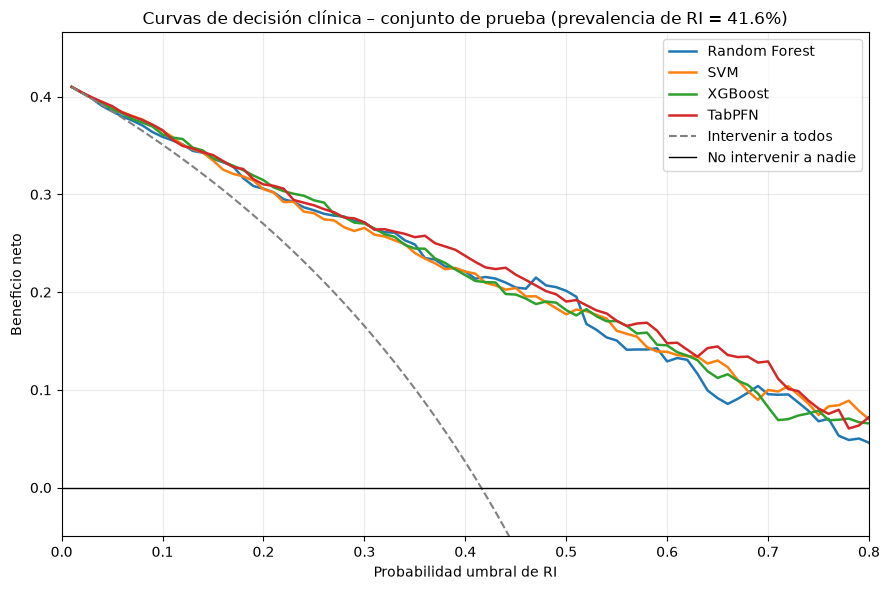

In [12]:
def beneficio_neto(y_true, y_prob, umbrales):
    """Beneficio neto del modelo para cada probabilidad umbral."""
    y_true = np.asarray(y_true)
    n = len(y_true)
    resultado = []
    for pt in umbrales:
        positivo = y_prob >= pt
        vp = np.sum(positivo & (y_true == 1))
        fp = np.sum(positivo & (y_true == 0))
        resultado.append(vp / n - fp / n * pt / (1 - pt))
    return np.array(resultado)


prevalencia = y_test.mean()
bn_intervenir_todos = prevalencia - (1 - prevalencia) * UMBRALES_DCA / (1 - UMBRALES_DCA)
bn_modelos = {nombre: beneficio_neto(y_test, r["y_prob"], UMBRALES_DCA) for nombre, r in resultados_test.items()}

fig, ax = plt.subplots(figsize=(9, 6))
for nombre, bn in bn_modelos.items():
    ax.plot(UMBRALES_DCA, bn, label=nombre, linewidth=1.8)
ax.plot(UMBRALES_DCA, bn_intervenir_todos, color="gray", linestyle="--", label="Intervenir a todos")
ax.axhline(0, color="black", linewidth=1, label="No intervenir a nadie")
ax.set_xlim(0, 0.8)
ax.set_ylim(-0.05, prevalencia + 0.05)
ax.set_xlabel("Probabilidad umbral de RI")
ax.set_ylabel("Beneficio neto")
ax.set_title(f"Curvas de decisión clínica – conjunto de prueba (prevalencia de RI = {prevalencia:.1%})")
ax.legend(loc="upper right")
ax.grid(alpha=0.25)
plt.tight_layout()
guardar_figura("dca_modelos.png")
plt.show()

In [13]:
# Beneficio neto en umbrales seleccionados y rango de umbrales con utilidad clínica
idx = [int(np.argmin(np.abs(UMBRALES_DCA - u))) for u in UMBRALES_DCA_TABLA]
tabla_dca = pd.DataFrame({nombre: bn[idx] for nombre, bn in bn_modelos.items()},
                         index=pd.Index(UMBRALES_DCA_TABLA, name="Umbral"))
tabla_dca["Intervenir a todos"] = bn_intervenir_todos[idx]
tabla_dca["No intervenir"] = 0.0

# Personas sin RI que se dejarían de intervenir por cada 100, frente a intervenir a todos
reduccion_intervenciones = {nombre: (bn[idx] - bn_intervenir_todos[idx])
                                    / (np.array(UMBRALES_DCA_TABLA) / (1 - np.array(UMBRALES_DCA_TABLA))) * 100
                            for nombre, bn in bn_modelos.items()}


def rango_util(bn):
    util = UMBRALES_DCA[(bn > bn_intervenir_todos) & (bn > 0)]
    return f"{util.min():.2f} – {util.max():.2f}" if len(util) else "ninguno"


print("Umbrales en los que cada modelo supera a 'intervenir a todos' y a 'no intervenir':")
for nombre, bn in bn_modelos.items():
    print(f"  {nombre:<14} {rango_util(bn)}")

print("\nIntervenciones innecesarias evitadas por cada 100 personas (vs. intervenir a todos):")
print(pd.DataFrame(reduccion_intervenciones, index=pd.Index(UMBRALES_DCA_TABLA, name="Umbral")).round(1).to_string())

tabla_dca = tabla_dca.round(4)
tabla_dca.to_csv(RESULTS_DIR / "tabla_dca.csv")
tabla_dca

Umbrales en los que cada modelo supera a 'intervenir a todos' y a 'no intervenir':
  Random Forest  0.02 – 0.96
  SVM            0.01 – 0.96
  XGBoost        0.01 – 0.98
  TabPFN         0.01 – 0.99

Intervenciones innecesarias evitadas por cada 100 personas (vs. intervenir a todos):
        Random Forest   SVM  XGBoost  TabPFN
Umbral                                      
0.1               7.2  12.7      9.4    13.3
0.2              14.4  14.2     17.9    16.2
0.3              24.7  23.4     24.4    24.7
0.4              29.2  29.2     28.7    31.6
0.5              37.0  34.6     35.0    35.9
0.6              39.3  40.0     40.4    40.6


,Random Forest,SVM,XGBoost,TabPFN,Intervenir a todos,No intervenir
Umbral,,,,,,
0.1,0.3589,0.3649,0.3613,0.3657,0.3508,0.0
0.2,0.3058,0.3053,0.3146,0.3102,0.2697,0.0
0.3,0.2713,0.2657,0.2701,0.2713,0.1654,0.0
0.4,0.2210,0.2210,0.2174,0.2371,0.0263,0.0
0.5,0.2013,0.1772,0.1816,0.1904,-0.1685,0.0
0.6,0.1291,0.1389,0.1455,0.1477,-0.4606,0.0


### 16.2 Calibración

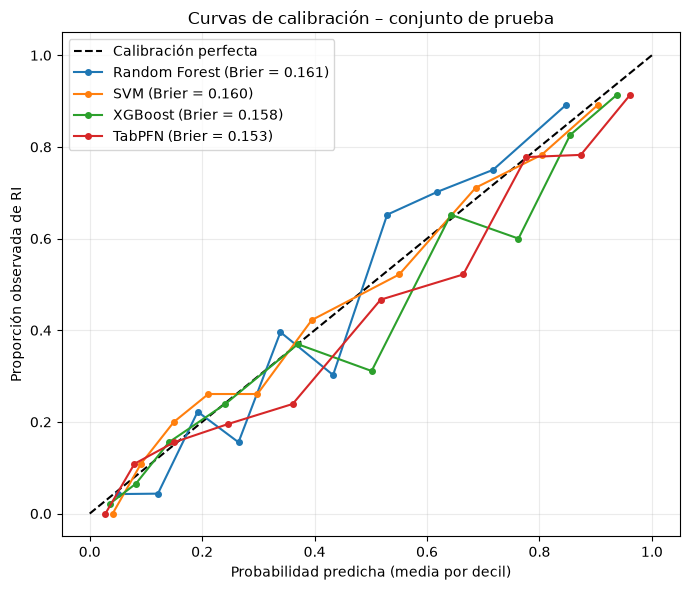

,Probabilidad media predicha,Prevalencia observada,Brier
Random Forest,0.4099,0.4158,0.1608
SVM,0.4131,0.4158,0.1599
XGBoost,0.4568,0.4158,0.1582
TabPFN,0.4657,0.4158,0.1527


In [14]:
fig, ax = plt.subplots(figsize=(7, 6))
ax.plot([0, 1], [0, 1], "k--", label="Calibración perfecta")
for nombre, r in resultados_test.items():
    frac_positivos, prob_media = calibration_curve(y_test, r["y_prob"], n_bins=10, strategy="quantile")
    ax.plot(prob_media, frac_positivos, marker="o", markersize=4,
            label=f"{nombre} (Brier = {r['metricas']['Brier']:.3f})")
ax.set_xlabel("Probabilidad predicha (media por decil)")
ax.set_ylabel("Proporción observada de RI")
ax.set_title("Curvas de calibración – conjunto de prueba")
ax.legend(loc="upper left")
ax.grid(alpha=0.25)
plt.tight_layout()
guardar_figura("calibracion_modelos.png")
plt.show()

pd.DataFrame({nombre: {"Probabilidad media predicha": r["y_prob"].mean(), "Prevalencia observada": prevalencia,
                       "Brier": r["metricas"]["Brier"]} for nombre, r in resultados_test.items()}).T.round(4)

## Resumen

In [15]:
display(metricas_test)
display(resumen_parsimonia)
print(f"Variables de consenso ({len(variables_consenso)}): {variables_consenso}")
display(pivote)
display(tabla_delong)
display(tabla_dca)

,AUC-ROC,PR-AUC,Sensibilidad,Especificidad,Accuracy,Precisión,F1,Brier
Random Forest,0.8408,0.7912,0.7105,0.8390,0.7856,0.7584,0.7337,0.1608
SVM,0.8409,0.7920,0.7105,0.7978,0.7615,0.7143,0.7124,0.1599
XGBoost,0.8496,0.8037,0.7579,0.7715,0.7659,0.7024,0.7291,0.1582
TabPFN,0.8606,0.8188,0.7737,0.7753,0.7746,0.7101,0.7406,0.1527


,Modelo,n_variables_85%,% del total (43 var)
0,Random Forest,18,41.9
1,XGBoost,18,41.9
2,TabPFN,16,37.2


Variables de consenso (11): ['IMC', 'CINTURA', 'TRIGLICERIDOS', 'COLESTEROL_HDL', 'CADERA', 'VITAMINA_D', 'ALT', 'PROTEINA_C_REACTIVA', 'PULSO', 'EDAD', 'HIERRO']


Conjunto de variables,Completo (43 var),Consenso (11 var),Diferencia AUC-ROC
Modelo,,,
RF,0.8508,0.8444,0.0064
SVM,0.8468,0.8420,0.0048
TabPFN,0.8653,0.8592,0.0061
XGBoost,0.8581,0.8512,0.0069


,Modelo,AUC completo,AUC consenso,Diferencia,z,p-valor,Significativo (α=0.05)
0,RF,0.8408,0.8355,0.0053,0.819,0.4129,No
1,SVM,0.8409,0.8345,0.0065,0.631,0.5278,No
2,XGBoost,0.8496,0.8352,0.0144,2.438,0.0148,Sí
3,TabPFN,0.8606,0.8506,0.0100,1.678,0.0933,No


,Random Forest,SVM,XGBoost,TabPFN,Intervenir a todos,No intervenir
Umbral,,,,,,
0.1,0.3589,0.3649,0.3613,0.3657,0.3508,0.0
0.2,0.3058,0.3053,0.3146,0.3102,0.2697,0.0
0.3,0.2713,0.2657,0.2701,0.2713,0.1654,0.0
0.4,0.2210,0.2210,0.2174,0.2371,0.0263,0.0
0.5,0.2013,0.1772,0.1816,0.1904,-0.1685,0.0
0.6,0.1291,0.1389,0.1455,0.1477,-0.4606,0.0
